In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss
from sklearn.preprocessing import LabelEncoder ,StandardScaler
import time



In [3]:
# Load the Dementia dataset
file_path = 'assessment-item1/dementia_data-MRI-features.csv'  # Replace with the actual path
dementia_df = pd.read_csv(file_path)


In [4]:
# Display the first few rows and check general info
print(dementia_df.head())
print(dementia_df.info())

# Check for missing values in each column
print("\nMissing values per column:")
print(dementia_df.isnull().sum())

  Subject ID         MRI ID        Group  Visit  MR Delay M/F Hand  Age  EDUC  \
0  OAS2_0001  OAS2_0001_MR1  Nondemented      1         0   M    R   87    14   
1  OAS2_0001  OAS2_0001_MR2  Nondemented      2       457   M    R   88    14   
2  OAS2_0002  OAS2_0002_MR1     Demented      1         0   M    R   75    12   
3  OAS2_0002  OAS2_0002_MR2     Demented      2       560   M    R   76    12   
4  OAS2_0002  OAS2_0002_MR3     Demented      3      1895   M    R   80    12   

   SES  MMSE  CDR  eTIV   nWBV    ASF  
0  2.0  27.0  0.0  1987  0.696  0.883  
1  2.0  30.0  0.0  2004  0.681  0.876  
2  NaN  23.0  0.5  1678  0.736  1.046  
3  NaN  28.0  0.5  1738  0.713  1.010  
4  NaN  22.0  0.5  1698  0.701  1.034  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    object 
 1   MRI ID      373 non-null    object 
 2  

In [5]:
# Drop irrelevant columns
dementia_df = dementia_df.drop(columns=['Subject ID', 'MRI ID', 'Hand'], errors='ignore')


In [6]:
# Encode categorical columns
dementia_df['Group'] = dementia_df['Group'].map({'Nondemented': 0, 'Demented': 1})
dementia_df['M/F'] = dementia_df['M/F'].map({'M': 0, 'F': 1})


In [7]:
# Fill missing values in 'SES' column with the median
dementia_df['SES'].fillna(dementia_df['SES'].median(), inplace=True)

C:\Users\msi 1\AppData\Local\Temp\ipykernel_15860\2319385739.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dementia_df['SES'].fillna(dementia_df['SES'].median(), inplace=True)


In [8]:
# Impute missing values for all columns based on their data type
for column in dementia_df.columns:
    if dementia_df[column].dtype in ['float64', 'int64']:  # Numeric columns
        dementia_df[column].fillna(dementia_df[column].median(), inplace=True)

C:\Users\msi 1\AppData\Local\Temp\ipykernel_15860\3919326584.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dementia_df[column].fillna(dementia_df[column].median(), inplace=True)
C:\Users\msi 1\AppData\Local\Temp\ipykernel_15860\3919326584.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behav

In [9]:
# Split data into features and target
X = dementia_df.drop(columns=['Group'])
y = dementia_df['Group']


In [10]:
# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [12]:
# Display preprocessed data
print("Preprocessed Dementia Data:")
print(pd.DataFrame(X_scaled, columns=X.columns).head())

Preprocessed Dementia Data:
      Visit  MR Delay       M/F       Age      EDUC       SES      MMSE  \
0 -0.957067 -0.937715 -1.153798  1.308738 -0.208132 -0.394466 -0.095686   
1  0.127997 -0.217613 -1.153798  1.439787 -0.208132 -0.394466  0.721664   
2 -0.957067 -0.937715 -1.153798 -0.263856 -0.904394 -0.394466 -1.185486   
3  0.127997 -0.055315 -1.153798 -0.132806 -0.904394 -0.394466  0.176764   
4  1.213060  2.048264 -1.153798  0.391392 -0.904394 -0.394466 -1.457936   

        CDR      eTIV      nWBV       ASF  
0 -0.777653  2.836059 -0.905169 -2.265742  
1 -0.777653  2.932703 -1.309643 -2.316501  
2  0.559050  1.079409  0.173429 -1.083784  
3  0.559050  1.420506 -0.446765 -1.344830  
4  0.559050  1.193108 -0.770344 -1.170800  


In [13]:
# Define a Gaussian Process Classifier with an RBF kernel
kernel = C(1.0) * RBF(length_scale=1.0)
gpc = GaussianProcessClassifier(kernel=kernel, random_state=42)


In [14]:
# Train the model
start_train_time = time.time()
gpc.fit(X_train, y_train)
train_time = time.time() - start_train_time

# Model Evaluation on the Test Set
start_test_time = time.time()
y_proba = gpc.predict_proba(X_test)[:, 1]  # Probability of being 'Demented' (class 1)
y_pred = gpc.predict(X_test)
test_time = time.time() - start_test_time

# Calculate Metrics
accuracy = accuracy_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)
kl_divergence = log_loss(y_test, y_proba)  # Log Loss approximates KL Divergence in binary classification
brier_score = brier_score_loss(y_test, y_proba)



In [15]:
# Print Results
print("Model Evaluation Metrics for Gaussian Process Classifier on Dementia Dataset:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Kullback-Leibler Divergence (Log Loss): {kl_divergence:.4f}")
print(f"Brier Score: {brier_score:.4f}")
print(f"Training Time: {train_time:.4f} seconds")
print(f"Testing Time: {test_time:.4f} seconds")

Model Evaluation Metrics for Gaussian Process Classifier on Dementia Dataset:
Accuracy: 0.9600
AUC: 0.9964
Kullback-Leibler Divergence (Log Loss): 0.0989
Brier Score: 0.0275
Training Time: 0.5908 seconds
Testing Time: 0.0100 seconds


In [16]:
# Queries for conditional probabilities
# Define two query data frames with evidence values for each query
query1 = {'Visit': 2, 'Age': 88, 'EDUC': 14, 'SES': 2, 'MMSE': 30, 'CDR': 0, 'eTIV': 2004, 'nWBV': 0.681, 'ASF': 0.876}
query2 = {'Visit': 3, 'Age': 80, 'EDUC': 12, 'MMSE': 22, 'CDR': 0.5, 'eTIV': 1698, 'nWBV': 0.701, 'ASF': 1.034}

# Convert queries to DataFrames and scale them
query_df1 = pd.DataFrame([query1])
query_df2 = pd.DataFrame([query2])

# Ensure query DataFrames have all necessary columns, with NaN for missing ones
for col in X.columns:
    if col not in query_df1.columns:
        query_df1[col] = np.nan
    if col not in query_df2.columns:
        query_df2[col] = np.nan

# Ensure column order matches training data
query_df1 = query_df1[X.columns]
query_df2 = query_df2[X.columns]

# Fill any remaining NaNs with median values from training data, then scale
for col in X.columns:
    query_df1[col].fillna(X_train[:, X.columns.get_loc(col)].mean(), inplace=True)
    query_df2[col].fillna(X_train[:, X.columns.get_loc(col)].mean(), inplace=True)

# Scale the queries
query_df1 = scaler.transform(query_df1)
query_df2 = scaler.transform(query_df2)

# Predict probabilities
proba_query1 = gpc.predict_proba(query_df1)[0]
proba_query2 = gpc.predict_proba(query_df2)[0]

# Display results
print("Results for Query 1:")
print(f"P(Group = Nondemented | evidence) = {proba_query1[0]:.4f}")
print(f"P(Group = Demented | evidence) = {proba_query1[1]:.4f}")

print("\nResults for Query 2:")
print(f"P(Group = Nondemented | evidence) = {proba_query2[0]:.4f}")
print(f"P(Group = Demented | evidence) = {proba_query2[1]:.4f}")

Results for Query 1:
P(Group = Nondemented | evidence) = 0.9517
P(Group = Demented | evidence) = 0.0483

Results for Query 2:
P(Group = Nondemented | evidence) = 0.0720
P(Group = Demented | evidence) = 0.9280


C:\Users\msi 1\AppData\Local\Temp\ipykernel_15860\2874027262.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  query_df1[col].fillna(X_train[:, X.columns.get_loc(col)].mean(), inplace=True)
C:\Users\msi 1\AppData\Local\Temp\ipykernel_15860\2874027262.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values al

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc,
    precision_recall_curve, PrecisionRecallDisplay
)
import numpy as np
from sklearn.calibration import calibration_curve

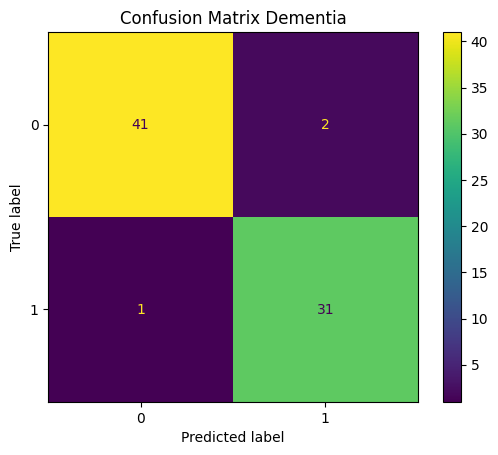

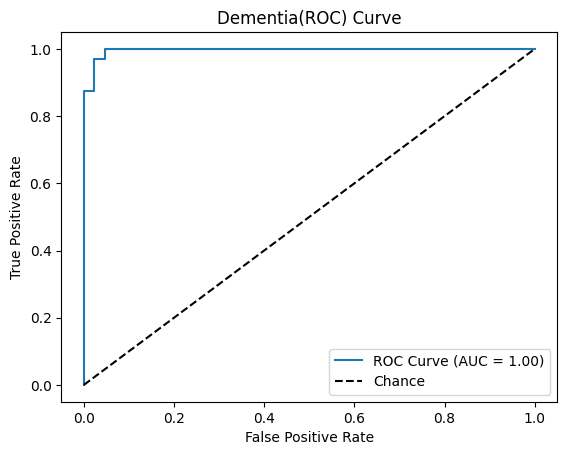

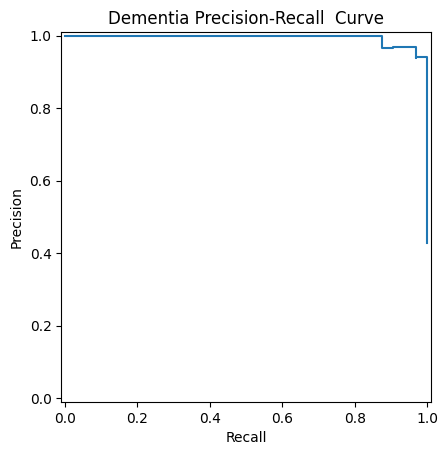

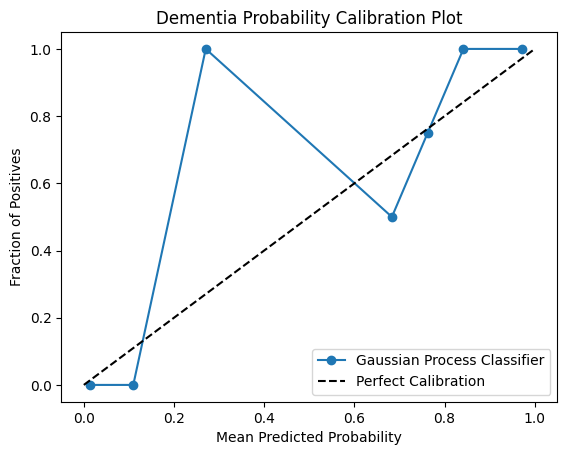

In [18]:


# Assuming y_test contains the true labels and y_proba contains the predicted probabilities
y_pred = (y_proba >= 0.5).astype(int)  # Classify based on probability threshold 0.5

# 1. Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(conf_matrix).plot()
plt.title("Confusion Matrix Dementia")
plt.show()

# 2. ROC Curve with AUC
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Dementia(ROC) Curve")
plt.legend()
plt.show()

# 3. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_proba)
PrecisionRecallDisplay(precision=precision, recall=recall).plot()
plt.title("Dementia Precision-Recall  Curve")
plt.show()

# 4. Probability Calibration Plot
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10)
plt.figure()
plt.plot(prob_pred, prob_true, marker='o', label="Gaussian Process Classifier")
plt.plot([0, 1], [0, 1], 'k--', label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Dementia Probability Calibration Plot")
plt.legend()
plt.show()
